# Train — ResNet-18 (scratch)

Trains and evaluates ResNet-18 (scratch) from random initial weights (no ImageNet pretraining), with the untuned `SCRATCH_HYPERPARAMS`, then saves its results and weights for the results notebooks.

In [1]:
from wwtw_utils import *

Using device: cuda
Test set ID: Fisantekraal
Train-time augmentation: on
Classes found (4): ['Dysfunctional', 'Empty', 'Functional', 'Scum']


## Data loaders and class weights

In [2]:
cfg = SCRATCH_HYPERPARAMS

# Batch sizes above MICRO_BATCH_CAP are reached with gradient accumulation.
micro_batch = min(cfg["batch_size"], MICRO_BATCH_CAP)
accum_steps = max(1, round(cfg["batch_size"] / micro_batch))
print(f"ResNet-18 (scratch): micro batch = {micro_batch}, accumulation steps = {accum_steps} "
      f"(effective batch size ≈ {micro_batch * accum_steps}, target = {cfg['batch_size']})")

train_ds_arch, val_ds_arch, test_ds_arch, train_loader_arch, val_loader_arch, test_loader_arch = \
    get_dataloaders(cfg["img_size"], micro_batch)

class_weights_arch = make_class_weights(train_ds_arch)

ResNet-18 (scratch): micro batch = 16, accumulation steps = 2 (effective batch size ≈ 32, target = 32)
Train: 1829 | Val: 446 | Test: 252


## Model

In [3]:
model = models.resnet18(weights=None)
in_f = model.fc.in_features
model.fc = build_classifier_head(in_f, cfg["hidden_layers"], cfg["neurons"], num_classes)

model = model.to(device)

criterion = nn.CrossEntropyLoss(weight=class_weights_arch)
optimizer = optim.Adam(
    model.parameters(),
    lr=cfg["lr"],
    betas=(cfg["beta1"], ADAM_BETA2),
    weight_decay=WEIGHT_DECAY,
)
scheduler = StepLR(optimizer, step_size=cfg["step_size"], gamma=0.1)

## Train

[ResNet-18 (scratch)] Gradient accumulation: 2 micro-batches per optimizer step.


[ResNet-18 (scratch)] Epoch   1/100 | LR: 1.00e-04 | train loss 1.1943 acc 0.454 | val loss 1.1659 acc 0.404 *


[ResNet-18 (scratch)] Epoch   2/100 | LR: 1.00e-04 | train loss 1.0066 acc 0.512 | val loss 0.9038 acc 0.543 *


[ResNet-18 (scratch)] Epoch   3/100 | LR: 1.00e-04 | train loss 0.9409 acc 0.538 | val loss 1.0069 acc 0.578


[ResNet-18 (scratch)] Epoch   4/100 | LR: 1.00e-04 | train loss 0.9303 acc 0.570 | val loss 0.8339 acc 0.628 *


...

[ResNet-18 (scratch)] Epoch  42/100 | LR: 1.00e-06 | train loss 0.3534 acc 0.843 | val loss 0.4613 acc 0.825


[ResNet-18 (scratch)] Epoch  43/100 | LR: 1.00e-06 | train loss 0.3249 acc 0.844 | val loss 0.4609 acc 0.809


[ResNet-18 (scratch)] Epoch  44/100 | LR: 1.00e-06 | train loss 0.3793 acc 0.829 | val loss 0.4583 acc 0.818


[ResNet-18 (scratch)] Epoch  45/100 | LR: 1.00e-07 | train loss 0.3716 acc 0.818 | val loss 0.4579 acc 0.807


[ResNet-18 (scratch)] Epoch  46/100 | LR: 1.00e-07 | train loss 0.3290 acc 0.831 | val loss 0.4583 acc 0.834

[ResNet-18 (scratch)] No val loss improvement for 10 epochs, stopping at epoch 46.

[ResNet-18 (scratch)] Restored best checkpoint (val loss = 0.4438)


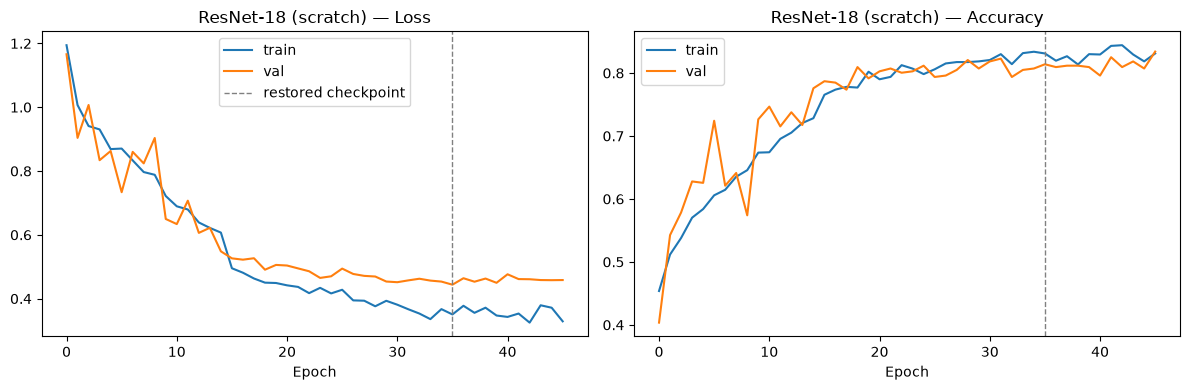

In [4]:
history = train_model(
    model, train_loader_arch, val_loader_arch, optimizer, scheduler,
    criterion, EPOCHS, EARLY_STOP_PATIENCE, "ResNet-18 (scratch)", is_inception=False,
    accum_steps=accum_steps,
)
plot_training_curves(history, "ResNet-18 (scratch)")

## Evaluate on the test set

[ResNet-18 (scratch)] Test accuracy: 0.726


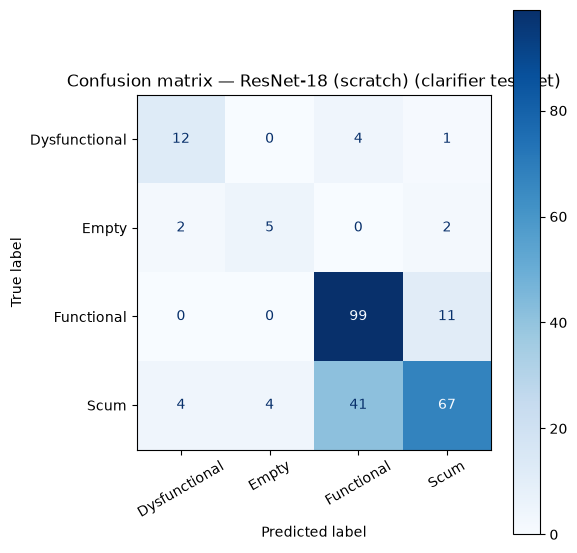

               precision    recall  f1-score   support

Dysfunctional      0.667     0.706     0.686        17
        Empty      0.556     0.556     0.556         9
   Functional      0.688     0.900     0.780       110
         Scum      0.827     0.578     0.680       116

     accuracy                          0.726       252
    macro avg      0.684     0.685     0.675       252
 weighted avg      0.746     0.726     0.719       252



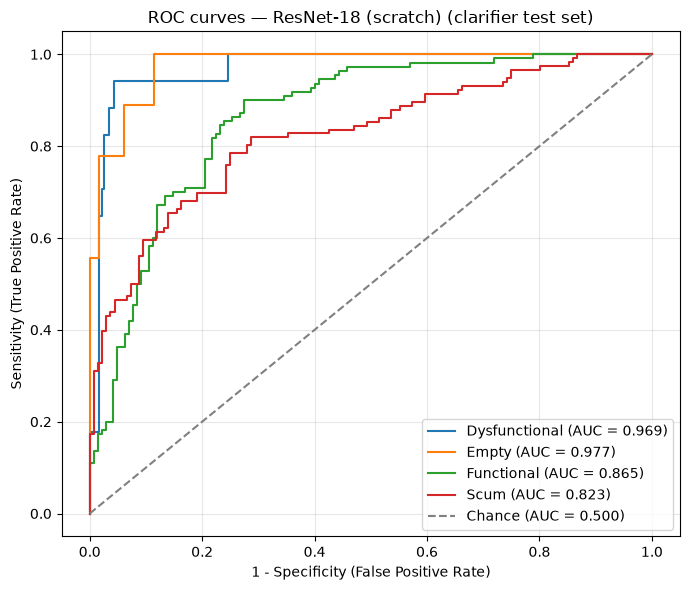

AUC (area under ROC curve) per class:
  Dysfunctional  : 0.969
  Empty          : 0.977
  Functional     : 0.865
  Scum           : 0.823

Mean AUC (over 4/4 classes with test examples): 0.908


(np.float64(0.7261904761904762),
 {'Dysfunctional': 0.9687108886107634,
  'Empty': 0.9766803840877915,
  'Functional': 0.8645326504481434,
  'Scum': 0.8225152129817446})

In [5]:
evaluate_and_record(
    model, test_loader_arch, "ResNet-18 (scratch)", history,
    img_size=cfg["img_size"], hidden_layers=cfg["hidden_layers"], neurons=cfg["neurons"],
    dev_loader=val_loader_arch,
)

## Save results and weights

In [6]:
save_result("ResNet-18 (scratch)", "resnet18_scratch")

Saved results to ../results/clarifier_aug/results_clarifier_resnet18_scratch_Fisantekraal.pkl
Saved model weights to ../models/pad/clarifier_aug/clarifier_resnet18_scratch_Fisantekraal.pt
